In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from PIL import Image

SEED = 42
import zipfile
import os

zip_path = "/content/FreshHarvest_Dataset.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/")

DATA_DIR = "/content/FreshHarvest_Dataset"   # change this to the path of your dataset folder
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 25

tf.random.set_seed(SEED)
np.random.seed(SEED)

In [ ]:
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp")
rows = []

for folder in sorted(os.listdir(DATA_DIR)):
    folder_path = os.path.join(DATA_DIR, folder)
    if not os.path.isdir(folder_path):
        continue
    if folder.startswith("F_"):
        label = 0   # fresh
    elif folder.startswith("S_"):
        label = 1   # spoiled
    else:
        continue
    for fname in os.listdir(folder_path):
        if fname.lower().endswith(VALID_EXT):
            rows.append({
                "path": os.path.join(folder_path, fname),
                "folder": folder,
                "fruit": folder[2:],
                "label": label,
            })

df = pd.DataFrame(rows)
print("Total images:", len(df))

Total images: 16000


In [ ]:
def is_ok(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

df = df[df["path"].apply(is_ok)].reset_index(drop=True)
print("Images after removing corrupt files:", len(df))

Images after removing corrupt files: 16000


status      fresh  spoiled
fruit                     
Banana       1000     1000
Lemon        1000     1000
Lulo         1000     1000
Mango        1000     1000
Orange       1000     1000
Strawberry   1000     1000
Tamarillo    1000     1000
Tomato       1000     1000


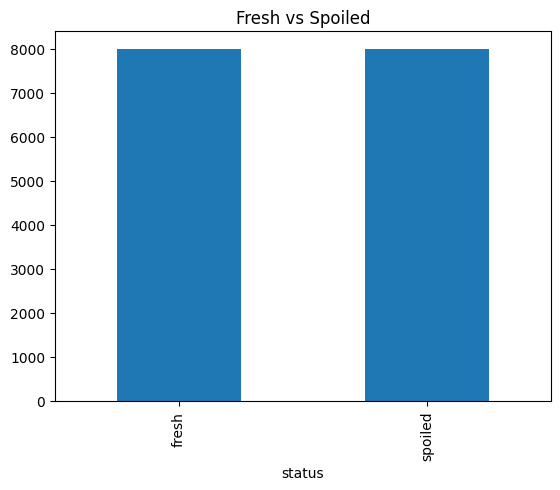

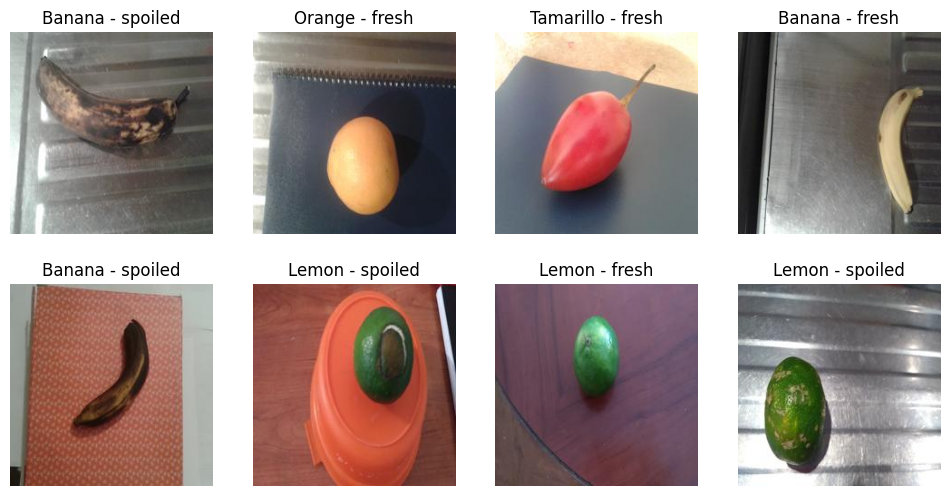

In [ ]:
df["status"] = df["label"].map({0: "fresh", 1: "spoiled"})
print(pd.crosstab(df["fruit"], df["status"]))

df["status"].value_counts().plot(kind="bar", title="Fresh vs Spoiled")
plt.show()

# Sample images
plt.figure(figsize=(12, 6))
sample = df.sample(8, random_state=SEED)
for i, (_, r) in enumerate(sample.iterrows()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(r["path"]))
    plt.title(f"{r['fruit']} - {r['status']}")
    plt.axis("off")
plt.show()

In [ ]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["folder"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["folder"], random_state=SEED)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

Train: 11200 Val: 2400 Test: 2400


In [ ]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_ds(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["path"].values, frame["label"].values.astype("float32")))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)   # not shuffled, so its order matches test_df

In [ ]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2),   # simulates inconsistent lighting
], name="augmentation")

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),   # output = probability of SPOILED
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,881 (1011.25 KB)

 Trainable params: 258,177 (1008.50 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
n_fresh = (train_df["label"] == 0).sum()
n_spoiled = (train_df["label"] == 1).sum()
total = n_fresh + n_spoiled
class_weight = {0: total / (2 * n_fresh), 1: total / (2 * n_spoiled)}

cbs = [
    callbacks.ModelCheckpoint("best_freshness_model.keras",
                              monitor="val_loss", save_best_only=True),
    callbacks.EarlyStopping(monitor="val_loss", patience=6,
                            restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=cbs)

Epoch 1/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.8161 - loss: 0.4128 - precision: 0.8338 - recall: 0.7895 - val_accuracy: 0.8096 - val_loss: 0.4078 - val_precision: 0.8555 - val_recall: 0.7450 - learning_rate: 0.0010
Epoch 2/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.8724 - loss: 0.3048 - precision: 0.8867 - recall: 0.8539 - val_accuracy: 0.9200 - val_loss: 0.2147 - val_precision: 0.9675 - val_recall: 0.8692 - learning_rate: 0.0010
Epoch 3/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.9046 - loss: 0.2381 - precision: 0.9114 - recall: 0.8964 - val_accuracy: 0.8517 - val_loss: 0.3718 - val_precision: 0.7890 - val_recall: 0.9600 - learning_rate: 0.0010
Epoch 4/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.9299 - loss: 0.1803 - precision: 0.9373 - recall: 0.9214 - val_accuracy: 0.8792 - val_loss: 0.3496 - val_precision: 0.8401 - val_recall: 0.9367 - learning_rate: 0.0010
Epoch 5/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 18s 50ms/step - 

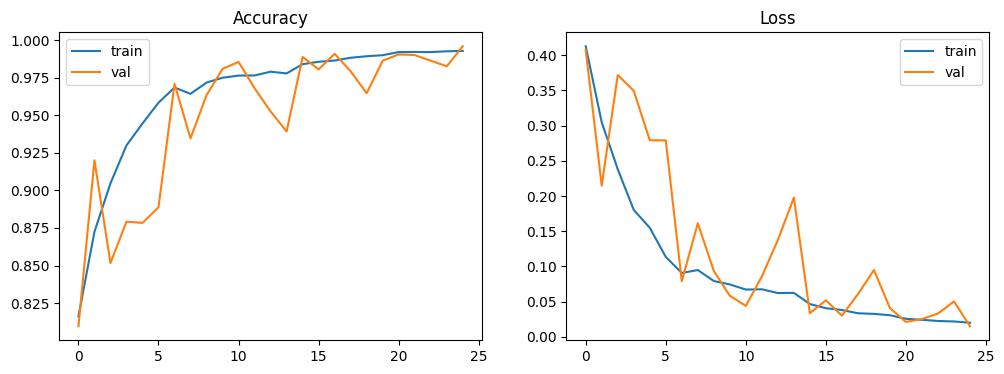

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step
              precision    recall  f1-score   support

       fresh       1.00      0.99      0.99      1200
     spoiled       0.99      1.00      0.99      1200

    accuracy                           0.99      2400
   macro avg       0.99      0.99      0.99      2400
weighted avg       0.99      0.99      0.99      2400



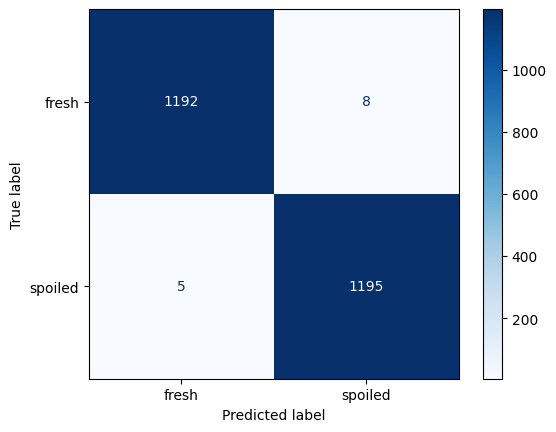

In [ ]:
model = tf.keras.models.load_model("best_freshness_model.keras")

probs = model.predict(test_ds).ravel()
preds = (probs > 0.5).astype(int)
y_true = test_df["label"].values

print(classification_report(y_true, preds, target_names=["fresh", "spoiled"]))

cm = confusion_matrix(y_true, preds)
ConfusionMatrixDisplay(cm, display_labels=["fresh", "spoiled"]).plot(cmap="Blues")
plt.show()

In [ ]:
test_df = test_df.copy()
test_df["correct"] = (preds == y_true)
print(test_df.groupby("fruit")["correct"].mean().round(3))

fruit
Banana        1.000
Lemon         1.000
Lulo          0.993
Mango         0.987
Orange        1.000
Strawberry    0.993
Tamarillo     0.990
Tomato        0.993
Name: correct, dtype: float64


In [ ]:
def predict_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    p = model.predict(tf.expand_dims(img, 0), verbose=0)[0][0]
    return ("spoiled", p) if p > 0.5 else ("fresh", 1 - p)

print(predict_image(test_df.iloc[0]["path"]))

('spoiled', np.float32(0.9998436))


In [ ]:
!python -c "import tensorflow as tf, keras; print(tf.__version__, keras.__version__)"

2.21.0 3.13.2


In [ ]:
pip install tensorflow==2.21.0 keras==3.13.2

In [ ]:
!python -c "import tensorflow as tf, keras; print(tf.__version__, keras.__version__)"

2.21.0 3.13.2
